# 06 - Transformer training (module 3, week 3)


Full fine-tuning of DistilBERT for multi-label emotion classification (28 labels), compared with the two classical references of the project:
- the **baseline** of `03_baseline.ipynb` (logistic regression, macro-F1 **0.477** on validation);
- the **best ensemble** of `05_ensembles.ipynb` (soft voting, macro-F1 **0.495**).

The checks of the pipeline (data, tokenizer, smoke test) are in `04_transformer.ipynb`.

**Protocol (same as notebooks 03 and 05):**
- train on train only; per-label thresholds tuned on validation with the shared `tune_thresholds`, **cross-fitted** (two halves of validation, same seed as notebook 05) for every score;
- models compared with the shared `paired_bootstrap` on the same validation comments;
- the **test set is never scored here**: only its probabilities are saved, for the final evaluation (module 4).

Runs on **Google Colab with a T4 GPU**. Every run is saved on Drive as soon as it ends, so a disconnection does not lose finished runs: re-running a cell skips the runs already saved.

In [1]:
import torch
print("PyTorch:", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

PyTorch: 2.14.1+cu130 | GPU: Tesla T4


In [2]:
!pip install -q transformers emoji

## 1. Setup

In [3]:
import os
import sys
import json
import time
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, set_seed

print("transformers:", transformers.__version__)

transformers: 5.22.1


In [4]:
from google.colab import drive
drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ML_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")
RUNS_DIR = os.path.join(PROJECT_DIR, "results", "transformer", "runs")
os.makedirs(RUNS_DIR, exist_ok = True)

# latest version of the repository: shared evaluation code (src/) and the results of notebooks 03 and 05
REPO = "/content/ML_Project"
if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check = True)
else:
    subprocess.run(["git", "clone", "https://github.com/lucaperkins/ML_Project", REPO], check = True)

Mounted at /content/drive


In [5]:
sys.path.append(os.path.join(REPO, "src"))
from evaluation import (LABELS_28, LEVELS, to_multi_hot, tune_thresholds, apply_thresholds,
                        compute_metrics, evaluate, paired_bootstrap, evaluate_all_levels, format_results, per_class_report)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. Data

The processed splits of `01_eda_simple.ipynb`, already on Drive (run `04_transformer.ipynb` first if they are missing). We use the cleaned `text` column, the same as the baseline.

In [6]:
assert os.path.exists(os.path.join(DATA_DIR, "train.parquet")), "Run 04_transformer.ipynb first to create the data on Drive"
df_train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
df_val = pd.read_parquet(os.path.join(DATA_DIR, "validation.parquet"))
df_test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))
assert (len(df_train), len(df_val), len(df_test)) == (43188, 5377, 5379), "Splits differ from 01_eda_simple.ipynb"

y_train = to_multi_hot(df_train["labels_28"], LABELS_28)   # 0/1 int, columns in LABELS_28 order
y_val = to_multi_hot(df_val["labels_28"], LABELS_28)
y_val_levels = {level: to_multi_hot(df_val[level], classes) for level, classes in LEVELS.items()}

suite = pd.read_csv(os.path.join(REPO, "src", "robustness_suite.csv"))   # hand-written messages of module 4
print("Train:", y_train.shape, "Validation:", y_val.shape, "Test:", len(df_test), "| Robustness suite:", len(suite), "messages")

Train: (43188, 28) Validation: (5377, 28) Test: 5379 | Robustness suite: 32 messages


## 3. Evaluation protocol and the two references

`crossfit_predict` is copied **exactly** from notebooks 03 and 05 (same halves, same seed), so the transformer is scored the same way as the classical models.

**Check:** recomputing the two references from their saved probabilities must give back 0.477 and 0.495. If it does, our protocol is identical to theirs.

In [7]:
SEED = 42

def crossfit_predict(y_true, proba, seed = SEED):
    """Same function as notebooks 03 and 05: thresholds tuned on one half of validation, applied to the other half."""
    rng = np.random.RandomState(seed)
    order = rng.permutation(len(y_true))
    half_a, half_b = order[: len(order) // 2], order[len(order) // 2 :]
    y_pred = np.zeros_like(y_true)
    for tune_idx, apply_idx in [(half_a, half_b), (half_b, half_a)]:
        thresholds_half = tune_thresholds(y_true[tune_idx], proba[tune_idx])
        y_pred[apply_idx] = apply_thresholds(proba[apply_idx], thresholds_half)
    return y_pred

proba_val_baseline = np.load(os.path.join(REPO, "results", "baselines", "proba_val_best.npy"))
proba_val_voting = np.load(os.path.join(REPO, "results", "ensembles", "proba_val_voting_soft.npy"))
y_pred_baseline = crossfit_predict(y_val, proba_val_baseline)
y_pred_voting = crossfit_predict(y_val, proba_val_voting)

references = pd.DataFrame([evaluate("baseline (03)", y_val, y_pred_baseline),
                           evaluate("soft voting (05)", y_val, y_pred_voting)])
format_results(references)[["model", "macro_f1", "micro_f1"]]

,model,macro_f1,micro_f1
0,baseline (03),"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]"
1,soft voting (05),"0.495 [0.474, 0.512]","0.550 [0.540, 0.559]"


## 4. Model, data loading and training loop

Same choices as the smoke test of `04_transformer.ipynb`, plus three standard additions for a full training:
- **learning-rate schedule:** linear warm-up over the first 10% of the steps, then linear decay to 0 (Devlin et al., 2019);
- **mixed precision (fp16):** about twice faster on a T4, with a gradient scaler so that small gradients are not rounded to 0;
- **evaluation after every epoch:** we keep the epoch with the best cross-fitted validation macro-F1.

**Weighted loss (option):** `pos_weight` gives more weight to the positive examples of rare emotions. We use the square root of the ratio negatives / positives (from 2 for neutral to about 24 for grief): the raw ratio (up to 560 for grief) makes the model predict rare emotions everywhere.

In [8]:
MAX_LEN = 64
BATCH_SIZE = 32
PLACEHOLDERS = ["[NAME]", "[RELIGION]"]   # found in 04_transformer.ipynb, step 2

class EmotionDataset(Dataset):
    def __init__(self, texts, labels = None):
        self.texts = list(texts)
        self.labels = labels
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, i):
        return self.texts[i], (None if self.labels is None else self.labels[i])

def make_collate(tokenizer):
    def collate(batch):
        texts, labels = zip(*batch)
        enc = tokenizer(list(texts), padding = True, truncation = True, max_length = MAX_LEN, return_tensors = "pt")
        if labels[0] is not None:
            enc["labels"] = torch.tensor(np.stack(labels), dtype = torch.float32)
        return enc
    return collate

def predict_proba(model, loader):
    """One probability per label (sigmoid of the logits), shape (n_texts, 28), in the order of the loader."""
    model.eval()
    probs = []
    with torch.no_grad():
        for batch in loader:
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = device.type == "cuda"):
                logits = model(input_ids = batch["input_ids"].to(device),
                               attention_mask = batch["attention_mask"].to(device)).logits
            probs.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.vstack(probs)

def make_pos_weight(y, kind):
    if kind is None:
        return None
    pos = y.sum(axis = 0)
    neg = len(y) - pos
    if kind == "sqrt":
        return torch.tensor(np.sqrt(neg / pos), dtype = torch.float32)
    raise ValueError(kind)

In [9]:
def run_name(cfg):
    name = f"{cfg['model'].split('/')[-1]}_lr{cfg['lr']:.0e}_seed{cfg['seed']}"
    return name + ("_posw-" + cfg["pos_weight"] if cfg["pos_weight"] else "")

def train_run(cfg):
    """Trains one configuration, keeps the best epoch (cross-fitted validation macro-F1) and saves on Drive:
    validation, test and robustness-suite probabilities (.npy, LABELS_28 order) and the training history.
    The test probabilities are saved for module 4 but never scored here."""
    out_dir = os.path.join(RUNS_DIR, run_name(cfg))
    if os.path.exists(os.path.join(out_dir, "history.json")):
        print("Already done, skipped:", run_name(cfg))
        return
    os.makedirs(out_dir, exist_ok = True)
    set_seed(cfg["seed"])

    tokenizer = AutoTokenizer.from_pretrained(cfg["model"])
    tokenizer.add_tokens(PLACEHOLDERS, special_tokens = True)
    collate = make_collate(tokenizer)
    train_loader = DataLoader(EmotionDataset(df_train["text"], y_train), batch_size = BATCH_SIZE, shuffle = True,
                              collate_fn = collate, generator = torch.Generator().manual_seed(cfg["seed"]))
    val_loader = DataLoader(EmotionDataset(df_val["text"], y_val), batch_size = 128, collate_fn = collate)
    test_loader = DataLoader(EmotionDataset(df_test["text"]), batch_size = 128, collate_fn = collate)
    suite_loader = DataLoader(EmotionDataset(suite["text"]), batch_size = 128, collate_fn = collate)

    model = AutoModelForSequenceClassification.from_pretrained(
        cfg["model"], num_labels = len(LABELS_28), problem_type = "multi_label_classification",
        id2label = dict(enumerate(LABELS_28)), label2id = {l: i for i, l in enumerate(LABELS_28)})
    model.resize_token_embeddings(len(tokenizer))
    model.to(device)

    pos_weight = make_pos_weight(y_train, cfg["pos_weight"])
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight = None if pos_weight is None else pos_weight.to(device))
    optimizer = torch.optim.AdamW(model.parameters(), lr = cfg["lr"], weight_decay = 0.01)
    n_steps = cfg["epochs"] * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * n_steps), n_steps)
    scaler = torch.amp.GradScaler(device.type, enabled = device.type == "cuda")

    history, best = [], {"macro_f1": -1}
    start = time.time()
    for epoch in range(1, cfg["epochs"] + 1):
        model.train()
        losses = []
        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type = device.type, dtype = torch.float16, enabled = device.type == "cuda"):
                logits = model(input_ids = batch["input_ids"], attention_mask = batch["attention_mask"]).logits
            loss = loss_fn(logits.float(), batch["labels"])
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            losses.append(loss.item())

        p_val = predict_proba(model, val_loader)
        macro_f1 = compute_metrics(y_val, crossfit_predict(y_val, p_val))["macro_f1"]
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_macro_f1": float(macro_f1),
                        "minutes": (time.time() - start) / 60})
        print(f"epoch {epoch}: train loss {np.mean(losses):.4f} | val macro-F1 (cross-fitted) {macro_f1:.3f} | {history[-1]['minutes']:.1f} min")
        if macro_f1 > best["macro_f1"]:
            best = {"macro_f1": float(macro_f1), "epoch": epoch, "p_val": p_val,
                    "p_test": predict_proba(model, test_loader), "p_suite": predict_proba(model, suite_loader)}

    np.save(os.path.join(out_dir, "proba_val.npy"), best["p_val"].astype(np.float32))
    np.save(os.path.join(out_dir, "proba_test.npy"), best["p_test"].astype(np.float32))
    np.save(os.path.join(out_dir, "proba_suite.npy"), best["p_suite"].astype(np.float32))
    with open(os.path.join(out_dir, "history.json"), "w") as f:
        json.dump({"config": cfg, "best_epoch": best["epoch"], "best_val_macro_f1": best["macro_f1"], "history": history}, f, indent = 2)
    print(f"Saved {run_name(cfg)}: best epoch {best['epoch']}, val macro-F1 {best['macro_f1']:.3f}")

    del model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

In [10]:
def load_run(cfg):
    out_dir = os.path.join(RUNS_DIR, run_name(cfg))
    with open(os.path.join(out_dir, "history.json")) as f:
        info = json.load(f)
    return info, np.load(os.path.join(out_dir, "proba_val.npy"))

def compare(cfgs):
    """Scores saved runs on validation (cross-fitted thresholds, bootstrap CI) and compares each one with
    the baseline and the soft voting with the paired bootstrap."""
    rows = []
    for cfg in cfgs:
        info, p_val = load_run(cfg)
        y_pred = crossfit_predict(y_val, p_val)
        row = evaluate(run_name(cfg), y_val, y_pred)
        row["best_epoch"] = info["best_epoch"]
        for ref_name, y_ref in [("baseline", y_pred_baseline), ("voting", y_pred_voting)]:
            p = paired_bootstrap(y_val, y_ref, y_pred)
            row["gain_vs_" + ref_name] = f"{p['diff_b_minus_a']:+.3f} [{p['ci_low']:+.3f}, {p['ci_high']:+.3f}]"
        rows.append(row)
    return format_results(pd.DataFrame(rows))[["model", "best_epoch", "macro_f1", "micro_f1", "gain_vs_baseline", "gain_vs_voting"]]

## 5. Step 3.1: first full training

One configuration: `distilbert-base-cased`, learning rate 5e-5 (the value of the smoke test), seed 42, 4 epochs. Expected time: about 10 to 15 minutes.

In [11]:
EPOCHS = 4
first_cfg = {"model": "distilbert-base-cased", "lr": 5e-5, "seed": SEED, "epochs": EPOCHS, "pos_weight": None}
train_run(first_cfg)

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  263MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.h

epoch 1: train loss 0.1601 | val macro-F1 (cross-fitted) 0.442 | 1.5 min
epoch 2: train loss 0.0841 | val macro-F1 (cross-fitted) 0.494 | 3.0 min
epoch 3: train loss 0.0680 | val macro-F1 (cross-fitted) 0.508 | 4.5 min
epoch 4: train loss 0.0545 | val macro-F1 (cross-fitted) 0.505 | 6.0 min
Saved distilbert-base-cased_lr5e-05_seed42: best epoch 3, val macro-F1 0.508


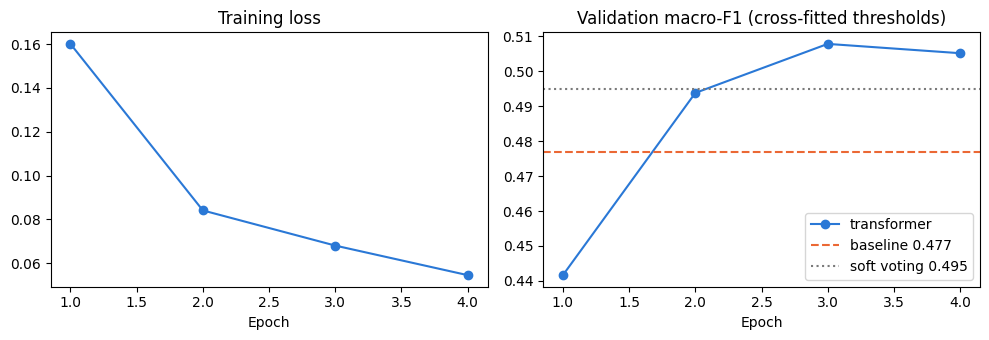

,epoch,train_loss,val_macro_f1,minutes
0,1,0.160,0.442,1.484
1,2,0.084,0.494,3.001
2,3,0.068,0.508,4.495
3,4,0.054,0.505,6.000


In [12]:
info, _ = load_run(first_cfg)
hist = pd.DataFrame(info["history"])
fig, axes = plt.subplots(1, 2, figsize = (10, 3.5))
axes[0].plot(hist["epoch"], hist["train_loss"], "o-", color = "#2a78d6")
axes[0].set_title("Training loss"); axes[0].set_xlabel("Epoch")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], "o-", color = "#2a78d6", label = "transformer")
axes[1].axhline(0.477, color = "#eb6834", linestyle = "--", label = "baseline 0.477")
axes[1].axhline(0.495, color = "#7a7a7a", linestyle = ":", label = "soft voting 0.495")
axes[1].set_title("Validation macro-F1 (cross-fitted thresholds)"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()
hist.round(3)

In [13]:
compare([first_cfg])

,model,best_epoch,macro_f1,micro_f1,gain_vs_baseline,gain_vs_voting
0,distilbert-base-cased_lr5e-05_seed42,3,"0.508 [0.487, 0.525]","0.582 [0.571, 0.592]","+0.031 [+0.010, +0.051]","+0.013 [-0.008, +0.035]"


**Findings of step 3.1.** The two references recomputed from their saved probabilities give exactly 0.477 and 0.495, so the transformer is scored with the same protocol as the classical models. DistilBERT (cased, learning rate 5e-5, seed 42) reaches a validation macro-F1 of 0.508 [0.487, 0.525] at epoch 3. It beats the baseline significantly (+0.031, paired bootstrap 95% CI [+0.010, +0.051]) and is ahead of the soft voting, but not significantly (+0.013 [-0.008, +0.035]). The validation score rises from 0.442 (epoch 1) to 0.508 (epoch 3), then stays flat (0.505 at epoch 4): 4 epochs are enough. One run takes 6 minutes on a T4 with mixed precision.

In [14]:
# Step 3.2: grid search on the learning rate (Lab 6), and steps 3.4 / 3.5: variants of the step 3.1 setting.
# The variants keep lr 5e-5 and seed 42, so only one thing changes at a time.
base_cfg = first_cfg
grid_cfgs = [dict(base_cfg, lr = lr) for lr in [2e-5, 3e-5, 5e-5]]
variant_cfgs = [dict(base_cfg, model = "distilbert-base-uncased"),   # 3.4: cased vs uncased
                dict(base_cfg, pos_weight = "sqrt")]                 # 3.5: weighted loss for rare emotions

for cfg in grid_cfgs + variant_cfgs:
    train_run(cfg)            # lr 5e-5 is already done, so it is skipped

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.1933 | val macro-F1 (cross-fitted) 0.393 | 1.5 min
epoch 2: train loss 0.0928 | val macro-F1 (cross-fitted) 0.459 | 3.0 min
epoch 3: train loss 0.0816 | val macro-F1 (cross-fitted) 0.475 | 4.5 min
epoch 4: train loss 0.0750 | val macro-F1 (cross-fitted) 0.485 | 6.1 min
Saved distilbert-base-cased_lr2e-05_seed42: best epoch 4, val macro-F1 0.485


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.1765 | val macro-F1 (cross-fitted) 0.422 | 1.5 min
epoch 2: train loss 0.0882 | val macro-F1 (cross-fitted) 0.479 | 3.0 min
epoch 3: train loss 0.0754 | val macro-F1 (cross-fitted) 0.500 | 4.5 min
epoch 4: train loss 0.0663 | val macro-F1 (cross-fitted) 0.504 | 6.0 min
Saved distilbert-base-cased_lr3e-05_seed42: best epoch 4, val macro-F1 0.504
Already done, skipped: distilbert-base-cased_lr5e-05_seed42


... (8 outputs left out)

epoch 1: train loss 0.1630 | val macro-F1 (cross-fitted) 0.462 | 1.5 min
epoch 2: train loss 0.0826 | val macro-F1 (cross-fitted) 0.501 | 3.0 min
epoch 3: train loss 0.0670 | val macro-F1 (cross-fitted) 0.502 | 4.5 min
epoch 4: train loss 0.0540 | val macro-F1 (cross-fitted) 0.503 | 6.0 min
Saved distilbert-base-uncased_lr5e-05_seed42: best epoch 4, val macro-F1 0.503


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.3445 | val macro-F1 (cross-fitted) 0.506 | 1.5 min
epoch 2: train loss 0.2123 | val macro-F1 (cross-fitted) 0.521 | 3.0 min
epoch 3: train loss 0.1621 | val macro-F1 (cross-fitted) 0.517 | 4.5 min
epoch 4: train loss 0.1268 | val macro-F1 (cross-fitted) 0.526 | 5.9 min
Saved distilbert-base-cased_lr5e-05_seed42_posw-sqrt: best epoch 4, val macro-F1 0.526


In [15]:
print("Grid search on the learning rate:")
display(compare(grid_cfgs))
print("Variants (lr 5e-5, seed 42):")
display(compare([base_cfg] + variant_cfgs))

Grid search on the learning rate:


,model,best_epoch,macro_f1,micro_f1,gain_vs_baseline,gain_vs_voting
0,distilbert-base-cased_lr2e-05_seed42,4,"0.485 [0.466, 0.501]","0.585 [0.575, 0.595]","+0.008 [-0.012, +0.028]","-0.010 [-0.030, +0.012]"
1,distilbert-base-cased_lr3e-05_seed42,4,"0.504 [0.485, 0.520]","0.587 [0.577, 0.597]","+0.026 [+0.009, +0.044]","+0.008 [-0.008, +0.027]"
2,distilbert-base-cased_lr5e-05_seed42,3,"0.508 [0.487, 0.525]","0.582 [0.571, 0.592]","+0.031 [+0.010, +0.051]","+0.013 [-0.008, +0.035]"


Variants (lr 5e-5, seed 42):


,model,best_epoch,macro_f1,micro_f1,gain_vs_baseline,gain_vs_voting
0,distilbert-base-cased_lr5e-05_seed42,3,"0.508 [0.487, 0.525]","0.582 [0.571, 0.592]","+0.031 [+0.010, +0.051]","+0.013 [-0.008, +0.035]"
1,distilbert-base-uncased_lr5e-05_seed42,4,"0.503 [0.483, 0.521]","0.583 [0.573, 0.593]","+0.026 [+0.005, +0.047]","+0.008 [-0.013, +0.029]"
2,distilbert-base-cased_lr5e-05_seed42_posw-sqrt,4,"0.526 [0.505, 0.544]","0.588 [0.578, 0.599]","+0.049 [+0.032, +0.068]","+0.031 [+0.013, +0.051]"


In [16]:
# Step 3.3: three seeds for the best setting (weighted loss) and for the unweighted one,
# to check that the gain of the weighted loss is larger than the variation due to the seed.
final_cfg = dict(base_cfg, pos_weight = "sqrt")
seed_cfgs = {"weighted (final)": [dict(final_cfg, seed = s) for s in [42, 43, 44]],
             "unweighted": [dict(base_cfg, seed = s) for s in [42, 43, 44]]}

for cfgs in seed_cfgs.values():      # the weighted runs first: they are the priority
    for cfg in cfgs:
        train_run(cfg)               # seed 42 is already done for both, so it is skipped

Already done, skipped: distilbert-base-cased_lr5e-05_seed42_posw-sqrt


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.3402 | val macro-F1 (cross-fitted) 0.503 | 1.5 min
epoch 2: train loss 0.2092 | val macro-F1 (cross-fitted) 0.523 | 3.0 min
epoch 3: train loss 0.1596 | val macro-F1 (cross-fitted) 0.509 | 4.5 min
epoch 4: train loss 0.1244 | val macro-F1 (cross-fitted) 0.510 | 6.0 min
Saved distilbert-base-cased_lr5e-05_seed43_posw-sqrt: best epoch 2, val macro-F1 0.523


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

epoch 1: train loss 0.1577 | val macro-F1 (cross-fitted) 0.450 | 1.5 min
epoch 2: train loss 0.0835 | val macro-F1 (cross-fitted) 0.504 | 3.0 min
epoch 3: train loss 0.0676 | val macro-F1 (cross-fitted) 0.499 | 4.5 min
epoch 4: train loss 0.0537 | val macro-F1 (cross-fitted) 0.509 | 5.9 min
Saved distilbert-base-cased_lr5e-05_seed43: best epoch 4, val macro-F1 0.509


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-cased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.1604 | val macro-F1 (cross-fitted) 0.450 | 1.5 min
epoch 2: train loss 0.0833 | val macro-F1 (cross-fitted) 0.488 | 3.0 min
epoch 3: train loss 0.0673 | val macro-F1 (cross-fitted) 0.498 | 4.5 min
epoch 4: train loss 0.0535 | val macro-F1 (cross-fitted) 0.503 | 5.9 min
Saved distilbert-base-cased_lr5e-05_seed44: best epoch 4, val macro-F1 0.503


In [17]:
rows = []
for name, cfgs in seed_cfgs.items():
    f1s = [compute_metrics(y_val, crossfit_predict(y_val, load_run(c)[1]))["macro_f1"] for c in cfgs]
    rows.append({"setting": name, "macro_f1 per seed (42, 43, 44)": [round(f, 3) for f in f1s],
                 "mean": np.mean(f1s), "std": np.std(f1s, ddof = 1)})
display(pd.DataFrame(rows).round(3))
display(compare(seed_cfgs["weighted (final)"]))

,setting,"macro_f1 per seed (42, 43, 44)",mean,std
0,weighted (final),"[0.526, 0.523, 0.516]",0.522,0.005
1,unweighted,"[0.508, 0.509, 0.503]",0.506,0.003


,model,best_epoch,macro_f1,micro_f1,gain_vs_baseline,gain_vs_voting
0,distilbert-base-cased_lr5e-05_seed42_posw-sqrt,4,"0.526 [0.505, 0.544]","0.588 [0.578, 0.599]","+0.049 [+0.032, +0.068]","+0.031 [+0.013, +0.051]"
1,distilbert-base-cased_lr5e-05_seed43_posw-sqrt,2,"0.523 [0.503, 0.540]","0.586 [0.575, 0.596]","+0.046 [+0.029, +0.063]","+0.027 [+0.010, +0.046]"
2,distilbert-base-cased_lr5e-05_seed44_posw-sqrt,2,"0.516 [0.495, 0.533]","0.584 [0.573, 0.593]","+0.039 [+0.021, +0.059]","+0.021 [+0.002, +0.040]"


In [18]:
# Step 3.6 a) Ensemble of the 3 seeds of the final setting: average of their probabilities (no new training).
# Like bagging in Lab 6, each seed sees the data in a different order and starts its head from different weights,
# so the three models make partly different errors and their average is more stable.
def load_proba(cfg, split):
    return np.load(os.path.join(RUNS_DIR, run_name(cfg), f"proba_{split}.npy"))

final_cfgs = seed_cfgs["weighted (final)"]
proba_ens = {split: np.mean([load_proba(c, split) for c in final_cfgs], axis = 0) for split in ["val", "test", "suite"]}

y_pred_ens = crossfit_predict(y_val, proba_ens["val"])
y_pred_best_seed = crossfit_predict(y_val, load_proba(final_cfgs[0], "val"))
row = evaluate("ensemble of 3 seeds (weighted loss)", y_val, y_pred_ens)
for ref_name, y_ref in [("baseline", y_pred_baseline), ("voting", y_pred_voting), ("seed 42 alone", y_pred_best_seed)]:
    p = paired_bootstrap(y_val, y_ref, y_pred_ens)
    row["gain_vs_" + ref_name] = f"{p['diff_b_minus_a']:+.3f} [{p['ci_low']:+.3f}, {p['ci_high']:+.3f}]"
format_results(pd.DataFrame([row]))[["model", "macro_f1", "micro_f1", "gain_vs_baseline", "gain_vs_voting", "gain_vs_seed 42 alone"]]

,model,macro_f1,micro_f1,gain_vs_baseline,gain_vs_voting,gain_vs_seed 42 alone
0,ensemble of 3 seeds (weighted loss),"0.524 [0.503, 0.541]","0.589 [0.579, 0.599]","+0.047 [+0.029, +0.066]","+0.029 [+0.010, +0.048]","-0.002 [-0.015, +0.010]"


In [25]:
# Step 3.6 b) Summary table of every run, for the report
all_cfgs = grid_cfgs + variant_cfgs + seed_cfgs["weighted (final)"][1:] + seed_cfgs["unweighted"][1:]
rows = []
for cfg in all_cfgs:
    info, p_val = load_run(cfg)
    m = compute_metrics(y_val, crossfit_predict(y_val, p_val))
    rows.append({"run": run_name(cfg), "model": cfg["model"].split("-")[-1], "lr": cfg["lr"], "seed": cfg["seed"],
                 "weighted_loss": bool(cfg["pos_weight"]), "best_epoch": info["best_epoch"],
                 "macro_f1": m["macro_f1"], "micro_f1": m["micro_f1"]})
m = compute_metrics(y_val, y_pred_ens)
rows.append({"run": "ensemble of 3 seeds (weighted loss)", "model": "cased", "lr": 5e-5, "seed": "42+43+44",
             "weighted_loss": True, "best_epoch": None, "macro_f1": m["macro_f1"], "micro_f1": m["micro_f1"]})
summary = pd.DataFrame(rows)
summary[["macro_f1", "micro_f1"]] = summary[["macro_f1", "micro_f1"]].round(3)
summary

,run,model,lr,seed,weighted_loss,best_epoch,macro_f1,micro_f1
0,distilbert-base-cased_lr2e-05_seed42,cased,0.00002,42,False,4.0,0.485,0.585
1,distilbert-base-cased_lr3e-05_seed42,cased,0.00003,42,False,4.0,0.504,0.587
2,distilbert-base-cased_lr5e-05_seed42,cased,0.00005,42,False,3.0,0.508,0.582
3,distilbert-base-uncased_lr5e-05_seed42,uncased,0.00005,42,False,4.0,0.503,0.583
4,distilbert-base-cased_lr5e-05_seed42_posw-sqrt,cased,0.00005,42,True,4.0,0.526,0.588
5,distilbert-base-cased_lr5e-05_seed43_posw-sqrt,cased,0.00005,43,True,2.0,0.523,0.586
6,distilbert-base-cased_lr5e-05_seed44_posw-sqrt,cased,0.00005,44,True,2.0,0.516,0.584
7,distilbert-base-cased_lr5e-05_seed43,cased,0.00005,43,False,4.0,0.509,0.588
8,distilbert-base-cased_lr5e-05_seed44,cased,0.00005,44,False,4.0,0.503,0.582
9,ensemble of 3 seeds (weighted loss),cased,0.00005,42+43+44,True,NaN,0.524,0.589


In [20]:
# Step 3.6 c) The final model at the three label levels, next to the baseline and the soft voting
levels = pd.concat([evaluate_all_levels("baseline (03)", y_pred_baseline, y_val_levels),
                    evaluate_all_levels("soft voting (05)", y_pred_voting, y_val_levels),
                    evaluate_all_levels("transformer (final)", y_pred_ens, y_val_levels)], ignore_index = True)
format_results(levels)[["model", "level", "macro_f1", "micro_f1"]]

,model,level,macro_f1,micro_f1
0,baseline (03),28,"0.477 [0.456, 0.495]","0.521 [0.512, 0.530]"
1,baseline (03),ekman,"0.546 [0.527, 0.564]","0.620 [0.611, 0.630]"
2,baseline (03),sentiment,"0.615 [0.604, 0.625]","0.646 [0.636, 0.655]"
3,soft voting (05),28,"0.495 [0.474, 0.512]","0.550 [0.540, 0.559]"
4,soft voting (05),ekman,"0.569 [0.551, 0.587]","0.643 [0.634, 0.652]"
5,soft voting (05),sentiment,"0.641 [0.630, 0.653]","0.668 [0.659, 0.677]"
6,transformer (final),28,"0.524 [0.503, 0.541]","0.589 [0.579, 0.599]"
7,transformer (final),ekman,"0.616 [0.597, 0.635]","0.695 [0.686, 0.705]"
8,transformer (final),sentiment,"0.691 [0.680, 0.704]","0.721 [0.712, 0.730]"


In [21]:
# Step 3.6 d) F1 per emotion: where does the transformer gain or lose against the baseline?
report_base = per_class_report(y_val, y_pred_baseline, LABELS_28)
report_tr = per_class_report(y_val, y_pred_ens, LABELS_28)
per_label = pd.DataFrame({"support (val)": report_base["support"], "train examples": pd.Series(y_train.sum(axis = 0), index = LABELS_28),
                          "baseline_f1": report_base["f1"], "transformer_f1": report_tr["f1"]})
per_label["gain"] = per_label["transformer_f1"] - per_label["baseline_f1"]
per_label = per_label.sort_values("gain", ascending = False).round(3)
per_label

,support (val),train examples,baseline_f1,transformer_f1,gain
caring,152,1082,0.331,0.475,0.144
disappointment,162,1267,0.203,0.338,0.135
disapproval,292,2020,0.310,0.445,0.135
pride,15,111,0.560,0.690,0.130
excitement,94,847,0.201,0.320,0.119
surprise,129,1056,0.440,0.555,0.115
approval,394,2938,0.290,0.394,0.104
annoyance,303,2468,0.280,0.383,0.103
confusion,149,1367,0.323,0.416,0.093
admiration,485,4118,0.654,0.735,0.081


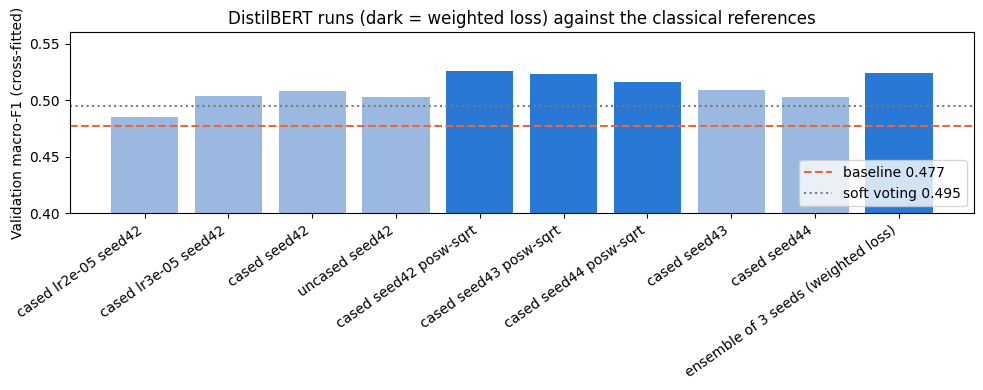

In [26]:
# Step 3.6 e) Figure for the report: macro-F1 of every run and of the references
fig, ax = plt.subplots(figsize = (10, 4))
names = list(summary["run"].str.replace("distilbert-base-", "").str.replace("_lr5e-05", "").str.replace("_", " "))
colors = ["#2a78d6" if w else "#9bb8e0" for w in summary["weighted_loss"]]
ax.bar(names, summary["macro_f1"], color = colors)
ax.axhline(0.477, color = "#eb6834", linestyle = "--", label = "baseline 0.477")
ax.axhline(0.495, color = "#7a7a7a", linestyle = ":", label = "soft voting 0.495")
ax.set_ylim(0.4, 0.56); ax.set_ylabel("Validation macro-F1 (cross-fitted)")
ax.set_title("DistilBERT runs (dark = weighted loss) against the classical references")
ax.legend(loc = "lower right")
plt.xticks(rotation = 35, ha = "right"); plt.tight_layout()
plt.savefig(os.path.join(RUNS_DIR, "..", "transformer_runs_macro_f1.png"), dpi = 150)
plt.show()

In [27]:
# Step 3.6 f) Save the final model's outputs in the shared format (.npy, (n, 28), LABELS_28 order, parquet row order)
# for Luca (vote), Myriam (calibration, robustness) and Faizan (error analysis). Test probabilities are not scored here.
FINAL_DIR = os.path.join(RUNS_DIR, "..", "final")
os.makedirs(FINAL_DIR, exist_ok = True)
assert proba_ens["val"].shape == (len(df_val), 28) and proba_ens["test"].shape == (len(df_test), 28)
np.save(os.path.join(FINAL_DIR, "proba_val_transformer.npy"), proba_ens["val"].astype(np.float32))
np.save(os.path.join(FINAL_DIR, "proba_test_transformer.npy"), proba_ens["test"].astype(np.float32))
np.save(os.path.join(FINAL_DIR, "proba_suite_transformer.npy"), proba_ens["suite"].astype(np.float32))
np.save(os.path.join(FINAL_DIR, "thresholds_transformer.npy"), tune_thresholds(y_val, proba_ens["val"]))   # whole validation, as in 03 and 05
summary.to_csv(os.path.join(FINAL_DIR, "validation_results_runs.csv"), index = False)
levels.to_csv(os.path.join(FINAL_DIR, "validation_results_levels.csv"), index = False)
per_label.to_csv(os.path.join(FINAL_DIR, "per_class_gain.csv"))
print("Saved in", FINAL_DIR, ":", sorted(os.listdir(FINAL_DIR)))

Saved in /content/drive/MyDrive/ML_Project/results/transformer/runs/../final : ['per_class_gain.csv', 'proba_suite_transformer.npy', 'proba_test_transformer.npy', 'proba_val_transformer.npy', 'thresholds_transformer.npy', 'validation_results_levels.csv', 'validation_results_runs.csv']


## Findings (validation set, cross-fitted thresholds, same protocol as notebooks 03 and 05)

- **Protocol check:** the two references recomputed from their saved probabilities give exactly 0.477 (baseline) and 0.495 (soft voting), so every model of the project is scored the same way.
- **Grid search on the learning rate (Lab 6):** 2e-5 gives 0.485, 3e-5 gives 0.504 and 5e-5 gives 0.508. With the two smaller rates the score is still rising at epoch 4: the model learns too slowly for 4 epochs. We keep 5e-5.
- **Cased vs uncased:** 0.508 vs 0.503, a difference within the variation between seeds. Keeping capital letters neither helps nor hurts; the fragmentation of words in capitals (AI_AUDIT.md, flaw 1) has no measurable effect.
- **Weighted loss for rare emotions:** the main gain. Over 3 seeds, macro-F1 is 0.522 ± 0.005 with the weighted loss against 0.506 ± 0.003 without it (+0.016, more than three times the standard deviation), and every weighted seed beats every unweighted seed. The weighted model also learns faster: its best epoch is often the second one.
- **Final model:** the average of the 3 weighted seeds (an ensemble in the spirit of bagging), macro-F1 0.524 [0.503, 0.541]. It is no better than the best single seed (-0.002, not significant) but does not depend on one lucky seed. It beats the baseline (+0.047 [+0.029, +0.066]) and the soft voting of the classical models (+0.029 [+0.010, +0.048]), both significantly with the paired bootstrap.
- **Three label levels:** 0.524 (28 labels), 0.616 (Ekman) and 0.691 (sentiment), against 0.495, 0.569 and 0.641 for the soft voting. The gap grows when close emotions are merged.
- **Per emotion:** the transformer improves 23 of the 28 emotions. The largest gains are on emotions expressed without a fixed word, which are the weak points of the bag-of-words baseline: caring (+0.14), disappointment (+0.14), disapproval (+0.14), excitement (+0.12), approval (+0.10), annoyance (+0.10). Emotions with an explicit cue word barely change (gratitude 0.90 for both). The only large loss is grief (-0.24), measured on 13 validation comments only, so one or two comments make the difference.
- **Cost:** one run takes 6 minutes on a T4 GPU with mixed precision, and the final model is 3 DistilBERT models (about 260 MB each), much heavier than the linear baseline (4 MB).
- **Limits:** the variants (uncased, learning rate) were tested with one seed only; the validation set was used both to select the configuration and to report these scores, so they are slightly optimistic. The final, unbiased comparison will be made once on the test set (module 4), with the saved test probabilities.